# Monte Carlo Stock Price & Portfolio Risk Simulator

This notebook simulates future equity prices using Geometric Brownian Motion (GBM). It starts with a single stock (AAPL): estimating historical return/volatility parameters, simulating thousands of possible price paths, and measuring downside risk with VaR/CVaR. It then extends the same approach to a 4-asset portfolio (AAPL, GS, JPM, MSFT), accounting for how the assets' returns move together.

In [1]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA


## Step 1: Pull historical data & estimate GBM parameters

Download 10 years of daily AAPL closing prices, compute daily log returns, and estimate the mean daily return and daily volatility from history — these are the drift and diffusion parameters the GBM simulation needs.

[*********************100%***********************]  1 of 1 completed

Ticker: AAPL
Data points: 2514
Mean daily return: 0.00101
Daily volatility: 0.01834
Latest close price: $334.77


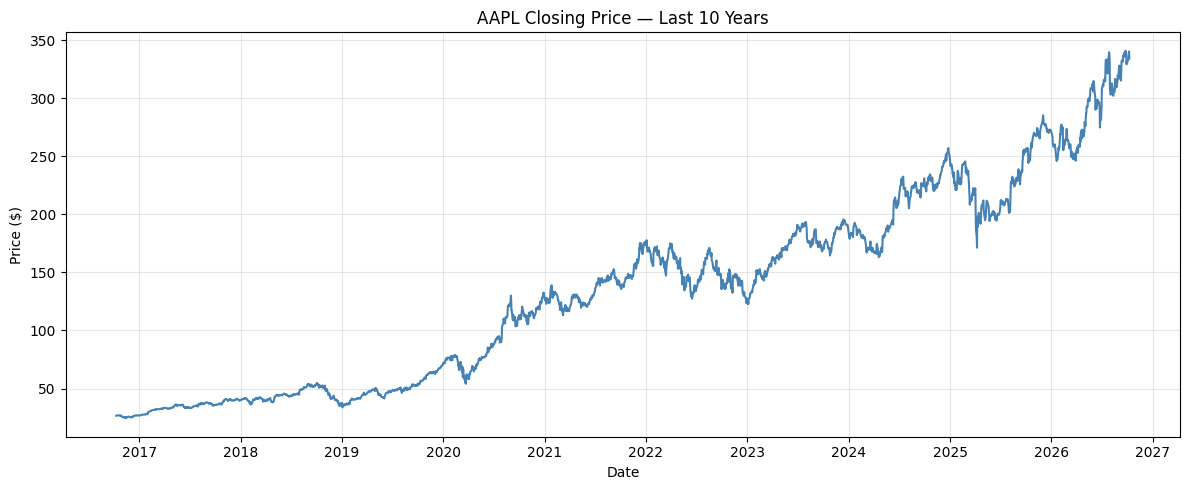

In [3]:
# Pull 10 years of Apple stock data
ticker = "AAPL"
data_aapl = yf.download(ticker, period="10y", auto_adjust=True)
prices = data_aapl['Close']

# Calculate daily returns
log_returns_aapl = np.log(prices / prices.shift(1))

# Estimate mean daily return and daily volatility from historical data
mean_return = log_returns_aapl.mean().item()
volatility = log_returns_aapl.std().item()

print(f"Ticker: {ticker}")
print(f"Data points: {len(prices)}")
print(f"Mean daily return: {mean_return:.5f}")
print(f"Daily volatility: {volatility:.5f}")
print(f"Latest close price: ${prices.iloc[-1].item():.2f}")

# Quick plot
plt.figure(figsize=(12, 5))
plt.plot(prices, color='steelblue')
plt.title(f'{ticker} Closing Price — Last 10 Years')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 2: Simulate future price paths (loop-based GBM)

For each of `num_simulations` hypothetical futures, walk forward day by day: draw a random standard-normal shock, apply the GBM daily return formula `(mean_return - 0.5*volatility**2) + volatility*Z`, and compound it onto the running price. This is the straightforward but slow way to generate simulated price paths.

In [4]:
# Monte Carlo simulation using GBM
prices_aapl = data_aapl['Close'].dropna()
num_simulations = 10000   # number of possible future paths to simulate
num_days = 252            # trading days in ~1 year — our forecast horizon

last_price = prices.iloc[-1].item()

# Matrix to hold all simulated price paths
simulation_results = np.zeros((num_days, num_simulations))

for sim in range(num_simulations):
    price_series = [last_price]
    for day in range(num_days):
        Z = np.random.normal(0, 1)  # random shock for this day
        daily_return = (mean_return) + volatility * Z
        new_price = price_series[-1] * np.exp(daily_return)
        price_series.append(new_price)
    simulation_results[:, sim] = price_series[1:]

print(f"Simulated {num_simulations} paths over {num_days} trading days")
print(f"Starting price: ${last_price:.2f}")
print(f"Mean ending price: ${simulation_results[-1].mean():.2f}")
print(f"Min ending price: ${simulation_results[-1].min():.2f}")
print(f"Max ending price: ${simulation_results[-1].max():.2f}")

Simulated 10000 paths over 252 trading days
Starting price: $334.77
Mean ending price: $450.71
Min ending price: $149.80
Max ending price: $1448.87


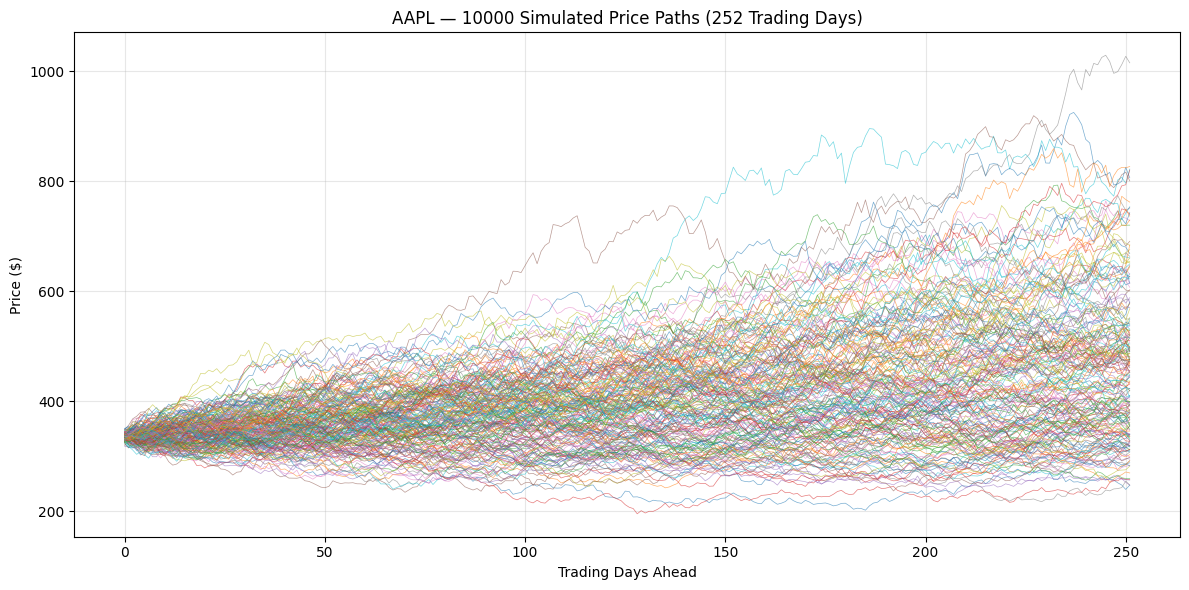

In [5]:
# Plot a sample of simulated paths
plt.figure(figsize=(12, 6))
plt.plot(simulation_results[:, :200], linewidth=0.5, alpha=0.6)  # plot first 200 paths
plt.title(f'{ticker} — {num_simulations} Simulated Price Paths ({num_days} Trading Days)')
plt.xlabel('Trading Days Ahead')
plt.ylabel('Price ($)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 3: Quantify downside risk (VaR & CVaR)

Convert the simulated ending prices into simple returns, then compute the 95% Value at Risk (the return threshold the worst 5% of outcomes fall below) and Conditional VaR (the average return within that worst 5% tail).

In [6]:
ending_prices = simulation_results[-1, :]
returns_simulated = (ending_prices - last_price) / last_price

confidence_level = 0.95
VaR_95 = np.percentile(returns_simulated, 5)
CVaR_95 = returns_simulated[returns_simulated <= VaR_95].mean()

print(f"Value at Risk (95% confidence): {VaR_95:.2%}")
print(f"Conditional Value at Risk (95% confidence): {CVaR_95:.2%}")

Value at Risk (95% confidence): -19.99%
Conditional Value at Risk (95% confidence): -28.00%


## Step 4: Vectorize the simulation

The double `for` loop above is slow at scale. Here the same GBM math is applied to every simulation and every day at once using NumPy array operations, producing statistically identical results in a fraction of the time.

In [7]:
# Vectorized Monte Carlo simulation using GBM

num_simulations = 10000   # number of possible future paths to simulate
num_days = 252

#Generating random shocks for all simulations at once
Z = np.random.normal(0,1, size=(num_days, num_simulations))

# Calculate daily returns for all simulations
daily_returns = mean_return + volatility * Z


# Cumulative returns for all simulations
cumulative_log_returns = np.cumsum(daily_returns, axis=0)

# Simulated price paths
simulation_results_vectorized = last_price * np.exp(cumulative_log_returns)

print(f'Mean ending price (vectorized): ${simulation_results_vectorized[-1].mean():.2f}')
print(f'Min ending price (vectorized): ${simulation_results_vectorized[-1].min():.2f}')
print(f'Max ending price (vectorized): ${simulation_results_vectorized[-1].max():.2f}')


Mean ending price (vectorized): $451.83
Min ending price (vectorized): $140.46
Max ending price (vectorized): $1387.64


In [8]:
expected_mean = last_price * np.exp(252 * (mean_return + 0.5 * volatility**2))
print(f"Simulated mean ending price: ${simulation_results_vectorized[-1].mean():.2f}")
print(f"Theoretical expected mean ending price: ${expected_mean:.2f}")

Simulated mean ending price: $451.83
Theoretical expected mean ending price: $450.34


In [9]:
print(simulation_results_vectorized.shape)
print(mean_return, volatility, last_price)
print(np.log(simulation_results_vectorized[-1] / last_price).mean() / num_days)

(252, 10000)
0.001008685474054464 0.0183361703263097 334.7690124511719
0.0010238276826804225


## Step 5: Extend to a multi-asset portfolio

The single-stock model above only accounts for one source of risk. To simulate a realistic portfolio we need historical data for multiple tickers and a way to capture how their returns move together — that means computing a covariance/correlation matrix instead of a single volatility number.

In [10]:
tickers = ['AAPL', 'GS', 'JPM', 'MSFT']
data_portfolio = yf.download(tickers, period="10y", auto_adjust=True)
log_returns_portfolio = np.log(data_portfolio['Close'] / data_portfolio['Close'].shift(1))
cov_matrix = log_returns_portfolio.cov()
correlation_matrix = log_returns_portfolio.corr()
print("Covariance Matrix:")
print(cov_matrix)


#Finding the correlation between the stocks
correlation_matrix = log_returns_portfolio.corr()
print("Correlation Matrix:")
print(correlation_matrix)


[*********************100%***********************]  4 of 4 completed

Covariance Matrix:
Ticker      AAPL        GS       JPM      MSFT
Ticker                                        
AAPL    0.000336  0.000157  0.000127  0.000204
GS      0.000157  0.000360  0.000263  0.000146
JPM     0.000127  0.000263  0.000296  0.000120
MSFT    0.000204  0.000146  0.000120  0.000305
Correlation Matrix:
Ticker      AAPL        GS       JPM      MSFT
Ticker                                        
AAPL    1.000000  0.451545  0.403116  0.635618
GS      0.451545  1.000000  0.803721  0.439772
JPM     0.403116  0.803721  1.000000  0.398464
MSFT    0.635618  0.439772  0.398464  1.000000


## Portfolio Monte Carlo (4 assets, correlated)

Simulating each stock independently would ignore the fact that AAPL, GS, JPM, and MSFT don't move in isolation — the correlation matrix above shows GS and JPM are especially tied together , likely from shared exposure to financial-sector and macro factors. If we generated independent random shocks per asset, the simulated portfolio would look far more diversified — and far less risky — than reality. So we use a Cholesky decomposition of the covariance matrix to inject the observed correlations into the simulated shocks before compounding them into price paths.

In [11]:
# Step 2: Per-asset mean daily return and volatility (as pandas Series, one column per ticker)
mean_returns = log_returns_portfolio.mean()
volatilities = log_returns_portfolio.std()

print("Mean Returns:")
print(mean_returns)
print("Volatilities:")
print(volatilities)

# Step 3: Cholesky decomposition of the covariance matrix.
# L is lower-triangular such that L @ L.T == cov_matrix; multiplying independent shocks
# by L.T injects the observed correlations between assets into the simulation.
L = np.linalg.cholesky(cov_matrix)

Mean Returns:
Ticker
AAPL    0.001009
GS      0.000738
JPM     0.000731
MSFT    0.000931
dtype: float64
Volatilities:
Ticker
AAPL    0.018336
GS      0.018975
JPM     0.017212
MSFT    0.017463
dtype: float64


In [12]:
num_simulations = 10000
num_days = 252

# Step 4: Generate independent standard normal shocks, one per asset per simulated day
Z = np.random.normal(size=(num_days, num_simulations, 4))

# Correlate the shocks using the Cholesky factor so simulated assets move together realistically
correlated_Z = Z @ L.T

# Step 5: Daily log returns per asset
# Note: correlated_Z already carries each asset's volatility, because L was derived from
# cov_matrix (variance units), not correlation_matrix -- so we add it directly rather than
# multiplying by volatilities again (that would double-apply vol and crush the variance).
daily_log_returns = (mean_returns.values) + correlated_Z

# Step 6: Cumulative log returns over the simulation horizon
cumulative_log_returns = np.cumsum(daily_log_returns, axis=0)

In [13]:
# Step 7: Starting price for each ticker — last row of the 4-ticker Close price data pulled above
start_prices = data_portfolio['Close'].dropna().iloc[-1].values  # shape (4,), order: AAPL, GS, JPM, MSFT

# Step 8: Convert cumulative log returns back into simulated price paths, shape (num_days, num_simulations, 4)
simulated_prices = start_prices * np.exp(cumulative_log_returns)

In [14]:
start_prices = data_portfolio['Close'].dropna().iloc[-1].values

# Step 9: Simple per-asset returns relative to the starting price, combined into an equal-weighted portfolio
asset_returns = simulated_prices / start_prices - 1  # (num_days, num_simulations, 4)
weights = np.array([0.25, 0.25, 0.25, 0.25])  # AAPL, GS, JPM, MSFT
portfolio_returns = asset_returns @ weights  # (num_days, num_simulations)

# Step 10: Portfolio value over time, summary stats, and VaR/CVaR risk metrics on the final day
portfolio_value = 10000 * (1 + portfolio_returns)  # starting portfolio value = $10,000
ending_values = portfolio_value[-1]

print(f"Mean ending portfolio value: ${ending_values.mean():.2f}")
print(f"5th percentile ending value: ${np.percentile(ending_values, 5):.2f}")
print(f"95th percentile ending value: ${np.percentile(ending_values, 95):.2f}")

final_day_returns = portfolio_returns[-1]
VaR_95 = np.percentile(final_day_returns, 5)
CVaR_95 = final_day_returns[final_day_returns <= VaR_95].mean()

print(f"Portfolio Value at Risk (95% confidence): {VaR_95:.2%}")
print(f"Portfolio Conditional Value at Risk (95% confidence): {CVaR_95:.2%}")

Mean ending portfolio value: $12949.58
5th percentile ending value: $8655.93
95th percentile ending value: $18407.58
Portfolio Value at Risk (95% confidence): -13.44%
Portfolio Conditional Value at Risk (95% confidence): -21.20%


In [43]:
# Monte Carlo simulation function for a portfolio of assets with optional fat-tailed shocks
def simulate_portfolio(weights, shock_type ="normal", num_sims = 10000, num_days = 252, df=5):
    n_assets = len(weights)

    if shock_type == "normal":
        Z = np.random.normal(size=(num_days, num_sims, n_assets))
    elif shock_type == "t":
        Z = stats.t.rvs(df=df, size=(num_days, num_sims, n_assets))
        Z = Z * np.sqrt((df - 2) / df)  # scale to variance 1
    else:
        raise ValueError("shock_type must be 'normal' or 't'")

    correlated_Z = Z @ L.T
    daily_log_returns = mean_returns.values + correlated_Z
    cumulative_log_returns = np.cumsum(daily_log_returns, axis=0)
    asset_returns = np.exp(cumulative_log_returns[-1]) - 1  # final day returns for each asset
    final_day_returns = asset_returns @ weights  # portfolio return on the final day

    return final_day_returns

In [40]:
w = np.array([0.25, 0.25, 0.25, 0.25])
r = simulate_portfolio(w)
print(r.shape)
print(np.percentile(r, 5), r[r <= np.percentile(r, 5)].mean())
print(simulate_portfolio(w, num_sims=500).shape)  

(10000,)
-0.1334753398872964 -0.20873925836254473
(500,)


In [45]:
w = np.array([0.25]*4)

def var_cvar(r, q=5) :
    v = np.percentile(r, q)
    return v, r[r <= v].mean()
normal_res = np.array([var_cvar(simulate_portfolio(w, "normal")) for _ in range(20)])
t_res = np.array([var_cvar(simulate_portfolio(w, "t")) for _ in range(20)])

print("Normal  VaR mean/std:", normal_res[:,0].mean(), normal_res[:,0].std())
print("t       VaR mean/std:", t_res[:,0].mean(),      t_res[:,0].std())
print("Normal CVaR mean/std:", normal_res[:,1].mean(), normal_res[:,1].std())
print("t      CVaR mean/std:", t_res[:,1].mean(),      t_res[:,1].std())

Normal  VaR mean/std: -0.13585761065926563 0.004007757237826793
t       VaR mean/std: -0.13646094493375055 0.004507274947634692
Normal CVaR mean/std: -0.21310652071211988 0.004663061350640963
t      CVaR mean/std: -0.2128145132917661 0.0057239292643169026


In [18]:
normal_1d = np.array([var_cvar(simulate_portfolio(w, "normal", num_days=1)) for _ in range(20)])
t_1d      = np.array([var_cvar(simulate_portfolio(w, "t",      num_days=1)) for _ in range(20)])
print(normal_1d.mean(axis=0), normal_1d.std(axis=0))
print(t_1d.mean(axis=0),      t_1d.std(axis=0))

[-0.02254994 -0.02840352] [0.00026066 0.00026925]
[-0.02181344 -0.02971149] [0.00028276 0.00040109]


In [28]:
#Comparing to the US treasury yield
rf = 0.0445

def risk_ratios(r, rf, threshold=None):
    threshold = rf if threshold is None else threshold
    excess = r - rf
    sharpe = excess.mean() / r.std()
    downside = np.sqrt(np.mean(np.minimum(excess, 0)**2))
    sortino = excess.mean() / downside
    omega = np.mean(np.maximum(r - threshold, 0)) / np.mean(np.maximum(threshold - r, 0))
    return sharpe, sortino, omega

r = simulate_portfolio(np.array([0.25]*4))
print("Sharpe, Sortino, Omega:", risk_ratios(r, rf))

Sharpe, Sortino, Omega: (0.8178892821555845, 3.426725593246044, 10.383349667010272)


In [29]:
for t in [0, 0.0445, 0.10, 0.20]:
    print(t, risk_ratios(r, rf, threshold=t)[2])

0 17.135423157805683
0.0445 10.383349667010272
0.1 5.797824720498174
0.2 2.2206838046402213


Max Sharpe: 0.8710100902874907 {'AAPL': 0.36, 'GS': 0.03, 'JPM': 0.28, 'MSFT': 0.34}
Min Volatility: 0.29353547396369234 {'AAPL': 0.19, 'GS': 0.06, 'JPM': 0.45, 'MSFT': 0.3}


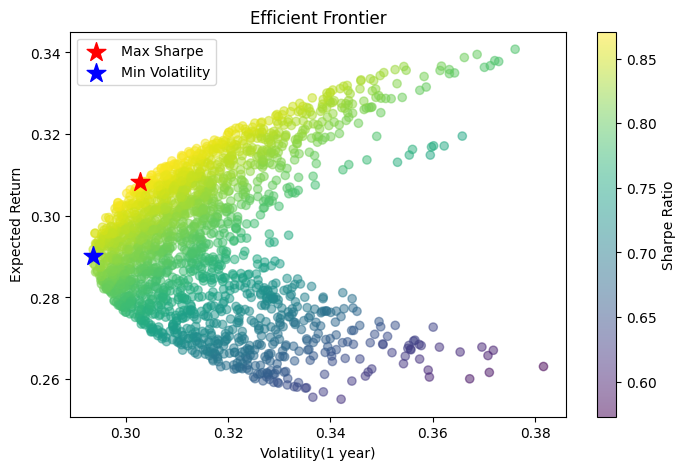

In [30]:
asset_ret = simulate_portfolio(np.eye(4))
W = np.random.dirichlet(np.ones(4), size=2000)
R = asset_ret @ W.T      # 10,000 random portfolio weights

exp_ret = R.mean(axis=0)
vol = R.std(axis=0)
sharpe = (exp_ret - rf) / vol

i_max, i_min = sharpe.argmax(), vol.argmin()
names = ['AAPL', 'GS', 'JPM', 'MSFT']
print("Max Sharpe:", sharpe[i_max], dict(zip(names, W[i_max].round(2))))
print("Min Volatility:", vol[i_min], dict(zip(names, W[i_min].round(2))))

plt.figure(figsize=(8,5))
plt.scatter(vol, exp_ret, c=sharpe, cmap='viridis', alpha=0.5)
plt.colorbar(label='Sharpe Ratio')
plt.scatter(vol[i_max], exp_ret[i_max], color='red', marker='*', s=200, label='Max Sharpe')
plt.scatter(vol[i_min], exp_ret[i_min], color='blue', marker='*', s=200, label='Min Volatility')
plt.xlabel("Volatility(1 year)")
plt.ylabel("Expected Return")
plt.title("Efficient Frontier")
plt.legend()
plt.show()


In [ ]:
# drift test function to scale the mean returns by a factor, allowing for testing different drift scenarios in the portfolio simulation.
def simulate_portfolio(weights, shock_type="normal", num_sims=10000, num_days=252, df=5, drift_scale = 1.0):
    n_assets = len(weights)

    if shock_type == "normal":
        Z = np.random.normal(size=(num_days, num_sims, n_assets))
    elif shock_type == "t":
        Z = stats.t.rvs(df=df, size=(num_days, num_sims, n_assets))
        Z = Z * np.sqrt((df - 2) / df)  # scale to variance 1
    else:
        raise ValueError("shock_type must be 'normal' or 't'")

    correlated_Z = Z @ L.T
    daily_log_returns = (mean_returns.values * drift_scale) + correlated_Z
    cumulative_log_returns = np.cumsum(daily_log_returns, axis=0)
    asset_returns = np.exp(cumulative_log_returns[-1]) - 1  # final day returns for each asset
    final_day_returns = asset_returns @ weights  # portfolio return on the final day

    return final_day_returns

In [37]:
# Testing different drift scenarios
from xgboost import cv


w = np.array([0.25]*4)
rf = 0.0445

print("Drift_Scale VaR CVaR Sharpe Sortino ")
for s in [1.0, 0.75, 0.5, 0.25, 0.0]:
    np.random.seed(0)
    r = simulate_portfolio(w, drift_scale=s)
    v = np.percentile(r, 5)
    c = r[r <= v].mean()
    sh, so, om = risk_ratios(r, rf)
    print(f"{s:<5} {v:.3f} {c:.4f} {sh:.2f} {so:.2f}")

Drift_Scale VaR CVaR Sharpe Sortino 
1.0   -0.132 -0.2112 0.84 3.63
0.75  -0.178 -0.2527 0.65 2.11
0.5   -0.221 -0.2919 0.44 1.12
0.25  -0.262 -0.3291 0.23 0.45
0.0   -0.301 -0.3642 0.00 0.01


## Step 6: Test the drift assumption with ARIMA

The simulation uses a flat historical mean as its drift. Here we test whether ARIMA(1,0,1) finds any predictable structure in AAPL's daily log-returns that would justify a time-varying drift instead: first by fitting on the full history (are the AR/MA coefficients statistically significant?), then with an out-of-sample train/test split, forecasting the held-out days and measuring the error (RMSE) against actual prices.


In [19]:
model = ARIMA(log_returns_portfolio['AAPL'].dropna(), order=(1, 0, 1))
fitted_model = model.fit()
print(fitted_model.summary())

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                 2513
Model:                 ARIMA(1, 0, 1)   Log Likelihood                6488.718
Date:                Fri, 09 Oct 2026   AIC                         -12969.435
Time:                        16:55:59   BIC                         -12946.118
Sample:                             0   HQIC                        -12960.972
                               - 2513                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0010      0.000      2.814      0.005       0.000       0.002
ar.L1         -0.4192      0.165     -2.539      0.011      -0.743      -0.096
ma.L1          0.3615      0.169      2.141      0.0

In [20]:
test_size = 100  # forecast horizon you're actually testing
train_size = len(prices_aapl) - test_size
train_returns = log_returns_aapl.iloc[:train_size]
test_returns = log_returns_aapl.iloc[train_size:]
train_prices = prices_aapl.iloc[:train_size]
test_prices = prices_aapl.iloc[train_size:]
print(f"Train: {len(train_returns)} days, Test: {len(test_returns)} days")

Train: 2414 days, Test: 100 days


In [21]:
model = ARIMA(train_returns['AAPL'].dropna(), order=(1, 0, 1))
fitted = model.fit()

forecasted_returns = fitted.forecast(steps=len(test_returns))

last_train_price = train_prices.iloc[-1].item()
forecast_prices = last_train_price * np.exp(forecasted_returns.cumsum())

print(forecast_prices.head())

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


2413    298.087557
2414    298.312019
2415    298.635665
2416    298.924698
2417    299.226354
Name: predicted_mean, dtype: float64


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


In [22]:
print((forecast_prices.values - test_prices.values).shape)

(100, 100)


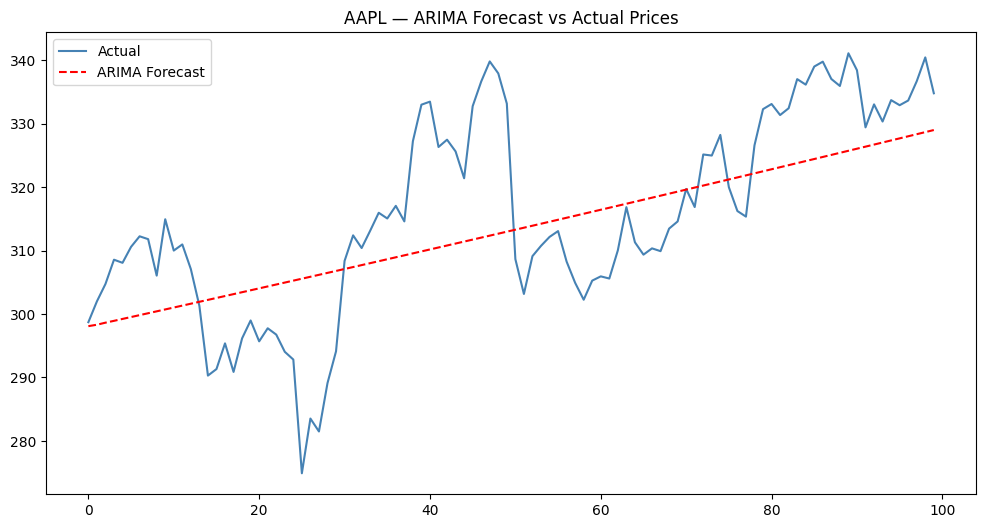

Root Mean Squared Error (RMSE) of ARIMA forecast: 11.61


In [23]:
plt.figure(figsize=(12, 6))
plt.plot(test_prices.values, label='Actual', color='steelblue')
plt.plot(forecast_prices.values, label='ARIMA Forecast', color='red', linestyle='--')
plt.legend()
plt.title(f'{ticker} — ARIMA Forecast vs Actual Prices')
plt.show()

rmse = np.sqrt(np.mean((forecast_prices.values - test_prices.values.flatten())**2))
print(f"Root Mean Squared Error (RMSE) of ARIMA forecast: {rmse:.2f}")

In [46]:
print("Overlapping breach rate:", (rolling_252d_returns < VaR_95).mean(), "over", len(rolling_252d_returns), "windows")

naive = np.full(len(test_prices), train_prices.iloc[-1].item())
print("Naive RMSE:", np.sqrt(np.mean((naive - test_prices.values.flatten())**2)))

Overlapping breach rate: 0.029177718832891247 over 2262 windows
Naive RMSE: 23.890997609421547


In [47]:
n = np.arange(1, len(test_prices) + 1)
drift_fc = train_prices.iloc[-1].item() * np.exp(train_returns['AAPL'].mean() * n)
print("Drift-only RMSE:", np.sqrt(np.mean((drift_fc - test_prices.values.flatten())**2)))

Drift-only RMSE: 11.625121804541962


## Step 7: Backtest the VaR estimate

Does the simulated 95% VaR hold up against real history? We build the portfolio's actual rolling 252-day returns (the same horizon as the simulated VaR) and count how often they fall below the VaR threshold. A well-calibrated 95% VaR should be breached about 5% of the time. Non-overlapping windows are used so each year is only counted once; with limited history this test has low statistical power, so treat the result as indicative rather than conclusive.


In [24]:
simple_returns = np.exp(log_returns_portfolio) - 1
historical_portfolio_returns = simple_returns @ weights   # daily portfolio returns (real data)

rolling_252d_returns = (1 + historical_portfolio_returns).rolling(252).apply(np.prod, raw=True) - 1
rolling_252d_returns = rolling_252d_returns.dropna()

non_overlapping = rolling_252d_returns.iloc[::252]
breaches = non_overlapping[non_overlapping < VaR_95]
print(f"Non-overlapping windows: {len(non_overlapping)}")
print(f"Breaches: {len(breaches)} ({len(breaches)/len(non_overlapping):.1%})")
# print(f"Number of VaR breaches in historical data: {breaches.sum()}")
# print(f"Breach rate: {breaches.sum()/len(rolling_252d_returns):.2%}  (expected: ~5.00%)")

Non-overlapping windows: 9
Breaches: 1 (11.1%)


In [25]:
print(breaches)
print(CVaR_95)

Date
2022-10-12   -0.200807
dtype: float64
-0.21196421625906642


## Step 8: Stress-test the Normal assumption with fat tails (Student-t)

Real market returns have heavier tails than a Normal distribution, so a Normal-shock simulation can understate extreme losses. We re-run the same portfolio simulation with Student-t shocks (df=5), rescaled to unit variance so that only the tail shape changes, not the overall volatility, and compare VaR and CVaR against the Normal version.


In [26]:
# Student-t shocks instead of Normal
degrees_of_freedom = 5
Z_t = stats.t.rvs(df=degrees_of_freedom, size=(num_days, num_simulations, 4))

# Rescaling 
scaling_factor = np.sqrt((degrees_of_freedom - 2) / degrees_of_freedom)
Z_t_scaled = Z_t * scaling_factor
print(Z_t_scaled.var())

1.0005928412099439


In [27]:
# Correlating the fat tailed shocks
correlated_Z_t = Z_t_scaled @ L.T

# Same GBM formula with fat-tailed shocks
daily_log_returns_t = (mean_returns.values ) + correlated_Z_t

cumulative_log_returns_t = np.cumsum(daily_log_returns_t, axis=0)
simulated_prices_t = start_prices * np.exp(cumulative_log_returns_t)

asset_returns_t = simulated_prices_t / start_prices - 1
portfolio_returns_t = asset_returns_t @ weights
portfolio_value_t = 10000 * (1 + portfolio_returns_t)

final_day_returns_t = portfolio_returns_t[-1]
VaR_95_t = np.percentile(final_day_returns_t, 5)
CVaR_95_t = final_day_returns_t[final_day_returns_t <= VaR_95_t].mean()

print(f"Student-t VaR (95%): {VaR_95_t:.2%}   (Normal VaR was {VaR_95:.2%})")
print(f"Student-t CVaR (95%): {CVaR_95_t:.2%}   (Normal CVaR was {CVaR_95:.2%})")

Student-t VaR (95%): -13.10%   (Normal VaR was -13.44%)
Student-t CVaR (95%): -20.88%   (Normal CVaR was -21.20%)
